# Earlier-Season Promotion Around New-Season Releases

**Business question:** When could Netflix promote earlier seasons around new-season releases to increase TV viewing hours?

This project uses Python/pandas to build release-aligned datasets from Netflix's global weekly Top 10, check older-season coverage, compare candidate promotion periods, and assess series/season differences. It proposes a randomized promotion test; no experiment has been run.

**Executive answer:** start with Weeks −1 to +5 for all-at-once releases and −1 to +10 for split releases, check series-specific timing, and keep season selection exploratory. Older-season presence is over 54 percentage points higher within these candidate windows in the selected sample. These windows were chosen from the same data: the difference describes concentration, not independent validation or promotion lift.

Scope: 5,480 TV chart records across 274 report weeks; 10 selected launches across 6 series; 21 launch-specific observations of 14 distinct older seasons. Top 10 absence does not mean zero viewing.

[Final 14-page presentation](../presentation/netflix-promotion-analysis.pdf) · [Methodology](../docs/data_and_methodology.md)

## 1. Load the frozen chart snapshot

Each source row is a chart-listed title/season in one category and reporting week. Filter to the two TV categories; no viewing-hour trend comparison is used to motivate the promotion recommendation.

In [1]:
from pathlib import Path
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:
    ROOT = Path.cwd().resolve()
    if not (ROOT / 'data').exists():
        ROOT = ROOT.parent
if not (ROOT / 'data').exists():
    raise FileNotFoundError('Run from the repository root or notebooks directory.')
OUT = ROOT / 'outputs' / 'tables'
OUT.mkdir(parents=True, exist_ok=True)
FIGURES = ROOT / 'outputs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
if 'display' not in globals():
    try:
        from IPython.display import display
    except ImportError:
        def display(value):
            if hasattr(value, 'data'):
                value = value.data
            if hasattr(value, 'to_string'):
                print(value.to_string(index=False))
            else:
                print(value)

import pandas as pd

data_path = ROOT / "data/all-weeks-global.tsv"
df = pd.read_csv(data_path, sep="\t")

df["week"] = pd.to_datetime(df["week"])

tv = df[
    df["category"].isin(["TV (English)", "TV (Non-English)"])
].copy()

print("Chart coverage:", tv["week"].min(), "to", tv["week"].max())
print("TV records:", len(tv))

display(tv.head())
display(tv.columns.to_list())

import sys
sys.path.insert(0, str(ROOT / "src"))

Chart coverage: 2021-07-04 00:00:00 to 2026-09-27 00:00:00
TV records: 5480


,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10
20,2026-09-27,TV (English),1,Monster: The Lizzie Borden Story,Monster: The Lizzie Borden Story: Season 1,95900000,6.6333,14500000.0,2
21,2026-09-27,TV (English),2,Wonka's The Golden Ticket,Wonka's The Golden Ticket: Season 1,28300000,6.1167,4600000.0,1
22,2026-09-27,TV (English),3,Crew Girl,Crew Girl: Season 1,28100000,6.2000,4500000.0,3
23,2026-09-27,TV (English),4,A Different World,A Different World: Season 1,23000000,5.4500,4200000.0,1
24,2026-09-27,TV (English),5,The Gentlemen,The Gentlemen: Season 2,31000000,7.4333,4200000.0,4


['week',
 'category',
 'weekly_rank',
 'show_title',
 'season_title',
 'weekly_hours_viewed',
 'runtime',
 'weekly_views',
 'cumulative_weeks_in_top_10']

## 2. Align release dates to report weeks

Week 0 is the Sunday-ending report week containing the first release or first episode batch. Later batches do not create extra launch events.

In [2]:
dates_path = ROOT / "data/season_release_dates.json"

release_dates = pd.read_json(dates_path)
release_dates["release_date"] = pd.to_datetime(
    release_dates["release_date"]
)

events = release_dates.loc[
    release_dates["season_number"].gt(1)
    & release_dates["release_date"].notna()
].copy()

events["launch_week"] = (
    events["release_date"]
    .dt.to_period("W-SUN")
    .dt.end_time
    .dt.normalize()
)

events = events.sort_values(["show_title", "season_number"])

display(events[[
    "show_title", "season_number",
    "release_date", "launch_week", "release_mode"
]])

,show_title,season_number,release_date,launch_week,release_mode
1,Bridgerton,2,2022-03-25,2022-03-27,all_at_once
2,Bridgerton,3,2024-05-16,2024-05-19,split_batches
3,Bridgerton,4,2026-01-29,2026-02-01,split_batches
5,DAN DA DAN,2,2025-07-03,2025-07-06,weekly
9,Manifest,4,2022-11-04,2022-11-06,split_batches
11,Ms. Rachel,2,2025-09-01,2025-09-07,all_at_once
13,Squid Game,2,2024-12-26,2024-12-29,all_at_once
14,Squid Game,3,2025-06-27,2025-06-29,all_at_once
16,Stranger Things,2,2017-10-27,2017-10-29,all_at_once
17,Stranger Things,3,2019-07-04,2019-07-07,all_at_once


## 3. Require complete 24-week charts

Keep Weeks −12 through +11, inclusive. Each category/week must contain ten entries and ranks 1–10. Complete charts allow a season to be coded as absent; a missing chart is not silently replaced by zero.

In [3]:
coverage = tv.groupby(["category", "week"])["weekly_rank"].agg(
    rows="size",
    ranks_ok=lambda x: set(x) == set(range(1, 11))
)
complete_weeks = set(
    coverage.index[coverage["rows"].eq(10) & coverage["ranks_ok"]]
)

show_categories = tv[["show_title", "category"]].drop_duplicates()

all_at_once_events = (
    events.loc[events["release_mode"].eq("all_at_once")]
    .merge(show_categories, on="show_title", validate="many_to_one")
)

all_at_once_events["full_24_weeks"] = all_at_once_events.apply(
    lambda e: all(
        (e["category"], e["launch_week"] + pd.Timedelta(weeks=r))
        in complete_weeks
        for r in range(-12, 12)
    ),
    axis=1
)

display(all_at_once_events[[
    "show_title", "season_number", "launch_week", "full_24_weeks"
]])

selected_events = all_at_once_events.loc[
    all_at_once_events["full_24_weeks"]
].copy()

print("Eligible events:", len(selected_events))

Eligible events: 4


,show_title,season_number,launch_week,full_24_weeks
0,Bridgerton,2,2022-03-27,True
1,Ms. Rachel,2,2025-09-07,True
2,Squid Game,2,2024-12-29,True
3,Squid Game,3,2025-06-29,True
4,Stranger Things,2,2017-10-29,False
5,Stranger Things,3,2019-07-07,False
6,The Gentlemen,2,2026-09-06,False


## 4. Identify older seasons for each launch

An older season has a smaller season number than the new season. The catalog comes from seasons observed somewhere in the frozen snapshot; a later audit checks it against the available release reference. The reference is not an exhaustive Netflix catalog.

In [4]:
tv["season_number"] = pd.to_numeric(
    tv["season_title"].str.extract(
        r"(?:Season|Part)\s+(\d+)", expand=False
    ),
    errors="coerce"
).astype("Int64")

season_catalog = tv[[
    "category", "show_title", "season_title", "season_number"
]].drop_duplicates()

event_old_seasons = selected_events[[
    "category", "show_title", "season_number", "launch_week"
]].rename(columns={"season_number": "new_season_number"}).merge(
    season_catalog.rename(columns={
        "season_title": "old_season_title",
        "season_number": "old_season_number"
    }),
    on=["category", "show_title"],
    how="inner"
)

event_old_seasons = event_old_seasons.loc[
    event_old_seasons["old_season_number"]
    < event_old_seasons["new_season_number"]
].sort_values(["show_title", "new_season_number", "old_season_number"])

display(event_old_seasons[[
    "show_title", "new_season_number",
    "old_season_title", "old_season_number", "launch_week"
]])

,show_title,new_season_number,old_season_title,old_season_number,launch_week
1,Bridgerton,2,Bridgerton: Season 1,1,2022-03-27
4,Ms. Rachel,2,Ms. Rachel: Season 1,1,2025-09-07
8,Squid Game,2,Squid Game: Season 1,1,2024-12-29
11,Squid Game,3,Squid Game: Season 1,1,2025-06-29
10,Squid Game,3,Squid Game: Season 2,2,2025-06-29


## 5. Construct the all-at-once weekly panel

Track every identified older season for all 24 weeks. A validated left join distinguishes chart absence from missing observation rows. Fill absent listings with zero only after complete-chart coverage is confirmed.

In [5]:
relative_weeks = pd.DataFrame({"relative_week": range(-12, 12)})

weekly_panel = event_old_seasons.merge(relative_weeks, how="cross")
weekly_panel["week"] = (
    weekly_panel["launch_week"]
    + pd.to_timedelta(weekly_panel["relative_week"] * 7, unit="D")
)

chart_keys = ["category", "show_title", "old_season_title", "week"]

observed = (
    tv[["category", "show_title", "season_title", "week"]]
    .rename(columns={"season_title": "old_season_title"})
    .drop_duplicates()
    .assign(in_top10=1)
)

weekly_panel = weekly_panel.merge(
    observed, on=chart_keys, how="left", validate="many_to_one"
)
weekly_panel["in_top10"] = (
    weekly_panel["in_top10"].fillna(0).astype(int)
)

weekly_matrix = weekly_panel.pivot(
    index=["show_title", "new_season_number", "old_season_title"],
    columns="relative_week",
    values="in_top10"
)

display(weekly_matrix)
print("Weekly panel rows:", len(weekly_panel))

Weekly panel rows: 120


relative_week                                      -12  -11  -10  ...   9    10   11
show_title new_season_number old_season_title                     ...               
Bridgerton 2                 Bridgerton: Season 1    0    0    0  ...    0    0    0
Ms. Rachel 2                 Ms. Rachel: Season 1    0    0    1  ...    0    0    0
Squid Game 2                 Squid Game: Season 1    0    0    0  ...    0    0    0
           3                 Squid Game: Season 1    0    0    0  ...    0    0    0
                             Squid Game: Season 2    0    0    0  ...    0    0    0

[5 rows x 24 columns]

## 6. Select split releases and harmonize season labels

Apply the same full-chart requirement. Reuse the original Stranger Things season-name corrections; missing labels are not automatically assigned to Season 1.

In [6]:
split_events = (
    events.loc[events["release_mode"].eq("split_batches")]
    .merge(show_categories, on="show_title", validate="many_to_one")
)

split_events["full_24_weeks"] = split_events.apply(
    lambda e: all(
        (e["category"], e["launch_week"] + pd.Timedelta(weeks=r))
        in complete_weeks
        for r in range(-12, 12)
    ),
    axis=1
)

display(split_events[[
    "show_title", "season_number", "launch_week", "full_24_weeks"
]])

selected_split_events = split_events.loc[
    split_events["full_24_weeks"]
].copy()

print("Eligible events:", len(selected_split_events))

Eligible events: 6


,show_title,season_number,launch_week,full_24_weeks
0,Bridgerton,3,2024-05-19,True
1,Bridgerton,4,2026-02-01,True
2,Manifest,4,2022-11-06,True
3,Stranger Things,4,2022-05-29,True
4,Stranger Things,5,2025-11-30,True
5,Wednesday,2,2025-08-10,True


In [7]:
split_tv = tv.copy()

mask = split_tv["show_title"].eq("Stranger Things") & (
    split_tv["season_title"].isna()
    | split_tv["season_title"].eq("Stranger Things 1")
)
split_tv.loc[mask, "season_title"] = "Stranger Things: Season 1"

season_num = split_tv["season_title"].str.extract(
    r"(?:Season|Part)\s+(\d+)", expand=False
)
special_num = split_tv["season_title"].str.extract(
    r"^Stranger Things\s+(\d+)$", expand=False
)
split_tv["season_number"] = pd.to_numeric(
    season_num.fillna(special_num), errors="coerce"
).astype("Int64")

split_catalog = split_tv[[
    "category", "show_title", "season_title", "season_number"
]].drop_duplicates()

split_old_seasons = selected_split_events[[
    "category", "show_title", "season_number", "launch_week"
]].rename(columns={"season_number": "new_season_number"}).merge(
    split_catalog.rename(columns={
        "season_title": "old_season_title",
        "season_number": "old_season_number"
    }),
    on=["category", "show_title"],
    how="inner"
)

split_old_seasons = split_old_seasons.loc[
    split_old_seasons["old_season_number"]
    < split_old_seasons["new_season_number"]
].sort_values(["show_title", "new_season_number", "old_season_number"])

display(split_old_seasons[[
    "show_title", "new_season_number",
    "old_season_title", "old_season_number"
]])

,show_title,new_season_number,old_season_title,old_season_number
1,Bridgerton,3,Bridgerton: Season 1,1
3,Bridgerton,3,Bridgerton: Season 2,2
5,Bridgerton,4,Bridgerton: Season 1,1
7,Bridgerton,4,Bridgerton: Season 2,2
6,Bridgerton,4,Bridgerton: Season 3,3
9,Manifest,4,Manifest: Season 1,1
11,Manifest,4,Manifest: Season 2,2
10,Manifest,4,Manifest: Season 3,3
15,Stranger Things,4,Stranger Things: Season 1,1
16,Stranger Things,4,Stranger Things 2,2


## 7. Construct the split-release weekly panel

Each split release is aligned once to its first batch. Later batch dates remain context rather than separately counted launches.

In [8]:
split_weekly_panel = split_old_seasons.merge(
    pd.DataFrame({"relative_week": range(-12, 12)}),
    how="cross"
)

split_weekly_panel["week"] = (
    split_weekly_panel["launch_week"]
    + pd.to_timedelta(split_weekly_panel["relative_week"] * 7, unit="D")
)

split_observed = (
    split_tv[["category", "show_title", "season_title", "week"]]
    .rename(columns={"season_title": "old_season_title"})
    .drop_duplicates()
    .assign(in_top10=1)
)

split_weekly_panel = split_weekly_panel.merge(
    split_observed,
    on=["category", "show_title", "old_season_title", "week"],
    how="left",
    validate="many_to_one"
)

split_weekly_panel["in_top10"] = (
    split_weekly_panel["in_top10"].fillna(0).astype(int)
)

split_weekly_matrix = split_weekly_panel.pivot(
    index=["show_title", "new_season_number", "old_season_title"],
    columns="relative_week",
    values="in_top10"
)

display(split_weekly_matrix)
print("Weekly panel rows:", len(split_weekly_panel))

Weekly panel rows: 384


relative_week                                                -12  -11  ...   10   11
show_title      new_season_number old_season_title                     ...          
Bridgerton      3                 Bridgerton: Season 1         0    0  ...    0    0
                                  Bridgerton: Season 2         0    0  ...    0    0
                4                 Bridgerton: Season 1         0    0  ...    0    0
                                  Bridgerton: Season 2         0    0  ...    0    0
                                  Bridgerton: Season 3         0    0  ...    0    0
Manifest        4                 Manifest: Season 1           1    1  ...    0    0
                                  Manifest: Season 2           1    1  ...    0    0
                                  Manifest: Season 3           1    0  ...    0    0
Stranger Things 4                 Stranger Things 2            0    0  ...    0    0
                                  Stranger Things 3            0    0  ...    1    0
                                  Stranger Things: Season 1    0    0  ...    0    0
                5                 Stranger Things 2            0    0  ...    0    0
                                  Stranger Things 3            0    0  ...    0    0
                                  Stranger Things 4            0    0  ...    0    0
                                  Stranger Things: Season 1    0    0  ...    0    0
Wednesday       2                 Wednesday: Season 1          0    0  ...    0    0

[16 rows x 24 columns]

## 8. Summarize weekly chart activity

Count older seasons separately for each launch. Squid Game S1 around the S2 and S3 releases contributes two observations. Raw counts across release formats have different sample sizes and do not measure a format advantage.

In [9]:
chart_data = weekly_panel.groupby(
    ["relative_week", "show_title", "new_season_number"]
)["in_top10"].sum().unstack(["show_title", "new_season_number"])

chart_data.columns = [
    f"{title} S{season}" for title, season in chart_data.columns
]
chart_data = chart_data.reindex(range(-12, 12))
chart_data.index.name = "relative_week"
chart_data = chart_data.reset_index()

display(chart_data)

chart_data.to_csv(
    OUT / "all_at_once_24week_chart_data.csv",
    index=False,
    encoding="utf-8-sig"
)

total_weekly = (
    weekly_panel.groupby("relative_week", as_index=False)
    .agg(total_old_seasons_in_top10=("in_top10", "sum"))
    .sort_values("relative_week")
)

display(total_weekly)

total_weekly.to_csv(
    OUT / "all_at_once_24week_total.csv",
    index=False,
    encoding="utf-8-sig"
)

split_total_weekly = (
    split_weekly_panel.groupby("relative_week", as_index=False)
    .agg(total_old_seasons_in_top10=("in_top10", "sum"))
    .sort_values("relative_week")
)

display(split_total_weekly)

split_total_weekly.to_csv(
    OUT / "split_batches_24week_total.csv",
    index=False,
    encoding="utf-8-sig"
)


panels = {"all_at_once": weekly_panel, "split_batches": split_weekly_panel}
event_rows = []
for mode, panel in panels.items():
    for (show, season), part in panel.groupby(["show_title", "new_season_number"]):
        event_rows.append({"release_mode": mode, "show_title": show,
            "new_season_number": int(season), "older_seasons": part.old_season_number.nunique()})
    panel.to_csv(OUT / f"{mode}_panel.csv", index=False)
event_sample = pd.DataFrame(event_rows)
event_sample.to_csv(OUT / "event_sample.csv", index=False)
display(event_sample)

,relative_week,Bridgerton S2,Ms. Rachel S2,Squid Game S2,Squid Game S3
0,-12,0,0,0,0
1,-11,0,0,0,0
2,-10,0,1,0,0
3,-9,0,1,0,0
4,-8,0,1,0,0
5,-7,0,1,0,0
6,-6,0,1,0,0
7,-5,0,1,0,0
8,-4,0,1,0,0
9,-3,0,1,0,0


,relative_week,total_old_seasons_in_top10
0,-12,0
1,-11,0
2,-10,1
3,-9,1
4,-8,1
5,-7,1
6,-6,1
7,-5,1
8,-4,1
9,-3,1


,relative_week,total_old_seasons_in_top10
0,-12,3
1,-11,2
2,-10,1
3,-9,2
4,-8,1
5,-7,0
6,-6,0
7,-5,0
8,-4,1
9,-3,1


,release_mode,show_title,new_season_number,older_seasons
0,all_at_once,Bridgerton,2,1
1,all_at_once,Ms. Rachel,2,1
2,all_at_once,Squid Game,2,1
3,all_at_once,Squid Game,3,2
4,split_batches,Bridgerton,3,2
5,split_batches,Bridgerton,4,3
6,split_batches,Manifest,4,3
7,split_batches,Stranger Things,4,3
8,split_batches,Stranger Things,5,4
9,split_batches,Wednesday,2,1


## 9. Check whether unlisted older seasons were excluded

Count an older season separately at each new-season launch. Compare the panel against the lower-numbered seasons in the existing release reference; a season absent throughout the 24-week window must not be excluded merely for having no listings.

The audit checks coverage of the available season list, not every season Netflix has released. Internal export field names retain `pair` and `metadata` for precise traceability; in the presentation these are explained as launch-specific older-season observations.

In [10]:
# Audit only: this section does not alter the original samples or chart indicators.
audit_event_keys = [
    "release_mode", "category", "show_title", "new_season_number", "launch_week"
]
audit_pair_keys = audit_event_keys + ["old_season_number"]

audit_events = pd.concat([
    selected_events.assign(release_mode="all_at_once"),
    selected_split_events.assign(release_mode="split_batches"),
], ignore_index=True).rename(columns={"season_number": "new_season_number"})
audit_events = audit_events[audit_event_keys].drop_duplicates()

# Use the existing release metadata as the reference, not the chart-derived catalog.
audit_known_seasons = release_dates[["show_title", "season_number"]].rename(
    columns={"season_number": "old_season_number"}
).drop_duplicates()
assert not audit_known_seasons.duplicated(["show_title", "old_season_number"]).any()

audit_expected = audit_events.merge(
    audit_known_seasons, on="show_title", how="left", validate="many_to_many"
)
audit_expected = audit_expected.loc[
    audit_expected.old_season_number.lt(audit_expected.new_season_number)
].copy()

# Check that the reference itself contains every lower-numbered season.
# Gaps are reported separately; they are not assumed to be real, available seasons.
audit_metadata_gaps = []
for event in audit_events.itertuples(index=False):
    known_numbers = set(audit_known_seasons.loc[
        audit_known_seasons.show_title.eq(event.show_title), "old_season_number"
    ].astype(int))
    for number in sorted(set(range(1, int(event.new_season_number))) - known_numbers):
        audit_metadata_gaps.append({
            "release_mode": event.release_mode,
            "show_title": event.show_title,
            "new_season_number": int(event.new_season_number),
            "missing_metadata_season_number": number,
        })
audit_metadata_gaps = pd.DataFrame(audit_metadata_gaps, columns=[
    "release_mode", "show_title", "new_season_number", "missing_metadata_season_number"
])

# split_tv already applies the Notebook's Stranger Things season-name harmonization.
# A season's presence anywhere in the frozen snapshot is different from its
# presence inside the 24-week launch window.
audit_snapshot_counts = (
    split_tv.dropna(subset=["season_number"])
    .groupby(["category", "show_title", "season_number"], as_index=False)
    .agg(snapshot_chart_weeks=("week", "nunique"))
    .rename(columns={"season_number": "old_season_number"})
)
audit_expected = audit_expected.merge(
    audit_snapshot_counts,
    on=["category", "show_title", "old_season_number"],
    how="left", validate="many_to_one",
)
audit_expected["snapshot_chart_weeks"] = (
    audit_expected.snapshot_chart_weeks.fillna(0).astype(int)
)

audit_existing_panel = pd.concat([
    weekly_panel.assign(release_mode="all_at_once"),
    split_weekly_panel.assign(release_mode="split_batches"),
], ignore_index=True)
assert not audit_existing_panel.duplicated(audit_pair_keys + ["relative_week"]).any()
audit_actual = audit_existing_panel.groupby(audit_pair_keys, as_index=False).agg(
    panel_rows=("relative_week", "size"),
    observed_panel_weeks=("relative_week", "nunique"),
    window_top10_weeks=("in_top10", "sum"),
)
audit_pairs = audit_expected.merge(
    audit_actual, on=audit_pair_keys, how="outer", validate="one_to_one",
    indicator="reference_panel_match",
)
assert not audit_pairs.reference_panel_match.eq("right_only").any(), (
    "The panel contains seasons missing from the existing release metadata."
)
audit_pairs["included_in_panel"] = audit_pairs.reference_panel_match.eq("both")
audit_pairs["not_observed_in_snapshot"] = audit_pairs.snapshot_chart_weeks.eq(0)
audit_pairs["omitted_not_observed_in_snapshot"] = (
    ~audit_pairs.included_in_panel & audit_pairs.not_observed_in_snapshot
)
audit_pairs["omitted_despite_snapshot_presence"] = (
    ~audit_pairs.included_in_panel & ~audit_pairs.not_observed_in_snapshot
)
audit_pairs["retained_zero_window"] = (
    audit_pairs.included_in_panel & audit_pairs.window_top10_weeks.eq(0)
)
audit_pairs["status"] = "retained_with_window_chart_presence"
audit_pairs.loc[audit_pairs.retained_zero_window, "status"] = "retained_zero_window"
audit_pairs.loc[audit_pairs.omitted_not_observed_in_snapshot, "status"] = (
    "omitted_not_observed_in_snapshot"
)
audit_pairs.loc[audit_pairs.omitted_despite_snapshot_presence, "status"] = (
    "omitted_despite_snapshot_presence"
)
for name in ["panel_rows", "observed_panel_weeks", "window_top10_weeks"]:
    audit_pairs[name] = audit_pairs[name].astype("Int64")
assert audit_pairs.loc[audit_pairs.included_in_panel, "panel_rows"].eq(24).all()
assert audit_pairs.loc[audit_pairs.included_in_panel, "observed_panel_weeks"].eq(24).all()
audit_pairs = audit_pairs.sort_values(audit_pair_keys).reset_index(drop=True)

audit_summary = audit_pairs.groupby("release_mode", as_index=False).agg(
    expected_event_season_pairs=("old_season_number", "size"),
    included_event_season_pairs=("included_in_panel", "sum"),
    omitted_not_observed_in_snapshot=("omitted_not_observed_in_snapshot", "sum"),
    omitted_despite_snapshot_presence=("omitted_despite_snapshot_presence", "sum"),
    retained_zero_window_pairs=("retained_zero_window", "sum"),
)
audit_summary = audit_events.groupby("release_mode").size().rename("launches").reset_index().merge(
    audit_summary, on="release_mode", validate="one_to_one"
)
audit_unique_seasons = audit_pairs[[
    "show_title", "old_season_number", "snapshot_chart_weeks"
]].drop_duplicates()

# Also show the limits of the reference: it is a selected list, not a complete
# Netflix catalog. An observed list cannot enumerate other never-charted series.
audit_metadata_coverage = audit_known_seasons.merge(
    audit_snapshot_counts.groupby(["show_title", "old_season_number"], as_index=False)
    .agg(snapshot_chart_weeks=("snapshot_chart_weeks", "sum")),
    on=["show_title", "old_season_number"], how="left", validate="one_to_one",
)
audit_metadata_coverage["snapshot_chart_weeks"] = (
    audit_metadata_coverage.snapshot_chart_weeks.fillna(0).astype(int)
)
audit_metadata_coverage["observed_in_snapshot"] = audit_metadata_coverage.snapshot_chart_weeks.gt(0)

display(audit_summary)
display(audit_pairs[[
    "release_mode", "show_title", "new_season_number", "old_season_number",
    "snapshot_chart_weeks", "window_top10_weeks", "included_in_panel", "status"
]])
print("Distinct metadata-listed older seasons for selected launches:", len(audit_unique_seasons))
print("Missing lower-season entries in the existing metadata:", len(audit_metadata_gaps))
print("Metadata seasons absent from the entire frozen chart snapshot:",
      int((~audit_metadata_coverage.observed_in_snapshot).sum()),
      "of", len(audit_metadata_coverage))
print("Reference scope: existing release metadata only; not a full Netflix catalog.")

for name, table in [
    ("older_season_coverage_summary", audit_summary),
    ("older_season_coverage_pairs", audit_pairs),
    ("older_season_metadata_coverage", audit_metadata_coverage),
    ("older_season_metadata_gaps", audit_metadata_gaps),
]:
    table.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")

Distinct metadata-listed older seasons for selected launches: 14
Missing lower-season entries in the existing metadata: 0
Metadata seasons absent from the entire frozen chart snapshot: 0 of 24
Reference scope: existing release metadata only; not a full Netflix catalog.


,release_mode,launches,expected_event_season_pairs,included_event_season_pairs,omitted_not_observed_in_snapshot,omitted_despite_snapshot_presence,retained_zero_window_pairs
0,all_at_once,4,5,5,0,0,0
1,split_batches,6,16,16,0,0,1


,release_mode,show_title,new_season_number,old_season_number,snapshot_chart_weeks,window_top10_weeks,included_in_panel,status
0,all_at_once,Bridgerton,2,1,20,6,True,retained_with_window_chart_presence
1,all_at_once,Ms. Rachel,2,1,26,11,True,retained_with_window_chart_presence
2,all_at_once,Squid Game,2,1,32,7,True,retained_with_window_chart_presence
3,all_at_once,Squid Game,3,1,32,3,True,retained_with_window_chart_presence
4,all_at_once,Squid Game,3,2,14,4,True,retained_with_window_chart_presence
5,split_batches,Bridgerton,3,1,20,8,True,retained_with_window_chart_presence
6,split_batches,Bridgerton,3,2,22,8,True,retained_with_window_chart_presence
7,split_batches,Bridgerton,4,1,20,4,True,retained_with_window_chart_presence
8,split_batches,Bridgerton,4,2,22,0,True,retained_zero_window
9,split_batches,Bridgerton,4,3,14,3,True,retained_with_window_chart_presence


### Coverage result

All **21 identified observations are included**, covering **14 distinct older seasons**. There are **zero exclusions** against the available reference. Bridgerton S2 around S4 remains included despite no listings in any of the 24 weeks. Seasons absent from the reference cannot be counted; this audit does not establish complete platform coverage.

## 10. Compare candidate periods with other observation weeks

Use the shared configuration: all-at-once **−1 to +5** (7 weeks), split release **−1 to +10** (12 weeks). These follow the observed patterns; they are not optimized or independently validated cutoffs.

**Observation unit:** one launch × one relative week. At least one older season listed gives 1; otherwise 0. Several older seasons listed in the same launch/week still count once. Compare rates rather than raw positive counts because the windows can differ in length.

Outside weeks are the remainder of the same −12 to +11 observation period: 17 weeks per all-at-once launch and 12 per split launch. Repeated weeks and repeated series are not independent launch samples; n remains 4 and 6.

In [11]:
from compare_windows import compare_candidate_windows

window_summary, window_by_launch, window_event_weeks = compare_candidate_windows({
    "all_at_once": weekly_panel,
    "split_batches": split_weekly_panel,
})

# Keep exported values numeric; format only the displayed summary.
window_display = window_summary[["release_mode", "launches"]].copy()
window_display["candidate_window"] = window_summary.apply(
    lambda r: f"{int(r.candidate_start_week):+d} to {int(r.candidate_end_week):+d}", axis=1
)
window_display["inside_window"] = window_summary.apply(
    lambda r: f"{r.candidate_positive_event_weeks}/{r.candidate_total_event_weeks} = {r.candidate_rate:.1%}", axis=1
)
window_display["remaining_weeks"] = window_summary.apply(
    lambda r: f"{r.noncandidate_positive_event_weeks}/{r.noncandidate_total_event_weeks} = {r.noncandidate_rate:.1%}", axis=1
)
window_display["difference_pp"] = window_summary.difference_percentage_points.round(1)
display(window_display)
display(window_by_launch[[
    "release_mode", "show_title", "new_season_number",
    "candidate_positive_weeks", "candidate_observed_weeks",
    "noncandidate_positive_weeks", "noncandidate_observed_weeks",
    "candidate_rate", "noncandidate_rate",
]])

for name, table in [
    ("candidate_window_summary", window_summary),
    ("candidate_window_by_launch", window_by_launch),
    ("candidate_window_event_weeks", window_event_weeks),
]:
    table.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")

,release_mode,launches,candidate_window,inside_window,remaining_weeks,difference_pp
0,all_at_once,4,-1 to +5,19/28 = 67.9%,9/68 = 13.2%,54.6
1,split_batches,6,-1 to +10,47/72 = 65.3%,8/72 = 11.1%,54.2


,release_mode,show_title,new_season_number,candidate_positive_weeks,candidate_observed_weeks,noncandidate_positive_weeks,noncandidate_observed_weeks,candidate_rate,noncandidate_rate
0,all_at_once,Bridgerton,2,6,7,0,17,0.857143,0.000000
1,all_at_once,Ms. Rachel,2,2,7,9,17,0.285714,0.529412
2,all_at_once,Squid Game,2,7,7,0,17,1.000000,0.000000
3,all_at_once,Squid Game,3,4,7,0,17,0.571429,0.000000
4,split_batches,Bridgerton,3,8,12,0,12,0.666667,0.000000
5,split_batches,Bridgerton,4,4,12,0,12,0.333333,0.000000
6,split_batches,Manifest,4,5,12,5,12,0.416667,0.416667
7,split_batches,Stranger Things,4,12,12,0,12,1.000000,0.000000
8,split_batches,Stranger Things,5,10,12,3,12,0.833333,0.250000
9,split_batches,Wednesday,2,8,12,0,12,0.666667,0.000000


### Candidate-window result

| Format | Candidate period | Inside | Other observation weeks | Difference |
|---|---|---:|---:|---:|
| All-at-once: 4 launches | −1 to +5 | 19/28 = 67.9% | 9/68 = 13.2% | +54.6 pp |
| Split release: 6 launches | −1 to +10 | 47/72 = 65.3% | 8/72 = 11.1% | +54.2 pp |

This supports candidate periods for promotion experiments within the selected chart-represented sample. It does not establish optimal timing, incremental viewing, or a difference in format effectiveness.

## 11. Check series-specific timing: Ms. Rachel

Compare all four all-at-once launches on the same 24-week timeline, using any older-season listing per launch/week. Ms. Rachel S1 is visible well before S2 launches, unlike the launch-concentrated patterns in the other sampled cases.

Also inspect the full first-to-last chart span. A broad first-to-last span can contain long gaps; it is not evidence of stable year-round viewing.

In [12]:
from series_timing import summarize_series_timing

series_timing, series_event_weeks, ms_rachel_snapshot = summarize_series_timing(panels, split_tv)
display(series_timing[["release_mode", "show_title", "new_season_number", "listed_weeks",
    "first_listed_week", "last_listed_week", "difference_percentage_points"]])
display(ms_rachel_snapshot)
for name, table in [("series_timing_by_launch", series_timing),
    ("series_timing_event_weeks", series_event_weeks), ("ms_rachel_snapshot", ms_rachel_snapshot)]:
    table.to_csv(OUT / f"{name}.csv", index=False)

,release_mode,show_title,new_season_number,listed_weeks,first_listed_week,last_listed_week,difference_percentage_points
0,all_at_once,Bridgerton,2,6,2022-03-27,2022-05-01,85.714286
1,all_at_once,Ms. Rachel,2,11,2025-06-29,2025-10-05,-24.369748
2,all_at_once,Squid Game,2,7,2024-12-22,2025-02-02,100.000000
3,all_at_once,Squid Game,3,4,2025-06-29,2025-07-20,57.142857
4,split_batches,Bridgerton,3,8,2024-05-12,2024-06-30,66.666667
5,split_batches,Bridgerton,4,4,2026-02-01,2026-03-08,33.333333
6,split_batches,Manifest,4,10,2022-08-14,2022-12-04,0.000000
7,split_batches,Stranger Things,4,12,2022-05-22,2022-08-07,100.000000
8,split_batches,Stranger Things,5,13,2025-11-02,2026-01-25,58.333333
9,split_batches,Wednesday,2,8,2025-08-03,2025-09-21,66.666667


,show_title,old_season_number,first_listed_week,last_listed_week,listed_weeks,first_to_last_calendar_weeks,longest_unlisted_gap_weeks
0,Ms. Rachel,1,2025-02-02,2026-07-05,26,75,38


### Series implication

Eight of ten launches have higher within-window chart presence; Manifest S4 is tied and Ms. Rachel S2 is lower. Within Ms. Rachel's 24-week window, older-season listings occur in Weeks −10 to −1 and +4 (11 weeks). Across the full snapshot, S1 appears in 26 of 75 first-to-last calendar weeks, including a 38-week unlisted gap.

**Implication:** check each series' timing pattern before applying a launch-window promotion plan. An evergreen or alternative timing strategy remains a hypothesis; the charts do not prove stable viewing or promotion effectiveness.

## 12. Compare previous and earlier seasons within the same candidate windows

Previous = immediately preceding season. Earlier = all seasons before the previous season. Restrict this secondary analysis to launches containing both groups: 1 all-at-once launch (Squid Game S3) and 5 split launches across 3 series.

**Metric:** for each season, divide listed weeks by candidate-window weeks. Average earlier seasons within each launch, then give launches equal weight. This avoids giving the earlier group more chances simply because it contains more seasons. It differs deliberately from the any-older-season weekly indicator used for timing.

In [13]:
from season_comparison import compare_season_groups

season_summary, season_by_launch, season_by_season, paired_seasons = compare_season_groups(panels)
display(season_summary)
display(paired_seasons[["release_mode", "show_title", "new_season_number", "previous_season",
    "earlier_seasons", "earlier_season_count", "difference_percentage_points"]])
for name, table in [("season_candidate_summary", season_summary),
    ("season_candidate_by_launch", season_by_launch), ("season_candidate_by_season", season_by_season),
    ("season_candidate_paired", paired_seasons)]:
    table.to_csv(OUT / f"{name}.csv", index=False)
for mode in panels:
    season_summary[season_summary.release_mode.eq(mode)].drop(columns="release_mode").to_csv(
        OUT / f"{mode}_previous_vs_earlier.csv", index=False)

,release_mode,old_season_group,mean_top10_weeks,mean_top10_share,launches,candidate_weeks,candidate_start_week,candidate_end_week
0,all_at_once,earlier_seasons,3.0,0.428571,1,7,-1,5
1,all_at_once,previous_season,4.0,0.571429,1,7,-1,5
2,split_batches,earlier_seasons,6.4,0.533333,5,12,-1,10
3,split_batches,previous_season,6.6,0.550000,5,12,-1,10


,release_mode,show_title,new_season_number,previous_season,earlier_seasons,earlier_season_count,difference_percentage_points
0,all_at_once,Squid Game,3,0.571429,0.428571,1,14.285714
1,split_batches,Bridgerton,3,0.666667,0.666667,1,0.000000
2,split_batches,Bridgerton,4,0.250000,0.166667,2,8.333333
3,split_batches,Manifest,4,0.083333,0.250000,2,-16.666667
4,split_batches,Stranger Things,4,0.916667,0.833333,2,8.333333
5,split_batches,Stranger Things,5,0.833333,0.750000,3,8.333333


### Season-targeting result

| Format | Previous-season share | Earlier-season mean share | Eligible launches |
|---|---:|---:|---:|
| All-at-once, −1 to +5 | 57.1% | 42.9% | 1 |
| Split release, −1 to +10 | 55.0% | 53.3% | 5 |

The all-at-once difference is a single Squid Game S3 observation. Split-release gaps average +1.7 pp, with 3 positive gaps, 1 tie and 1 negative gap (Manifest S4: −16.7 pp). The small average does not establish equivalence or absence of a meaningful difference. Neither sample supports a general season-group priority.

## 13. Create presentation-consistent charts

Red highlights candidate periods; neutral colors distinguish season groups without implying a recommended winner. Counts use different format-specific denominators. SVG and PNG exports are regenerated from the same tables.

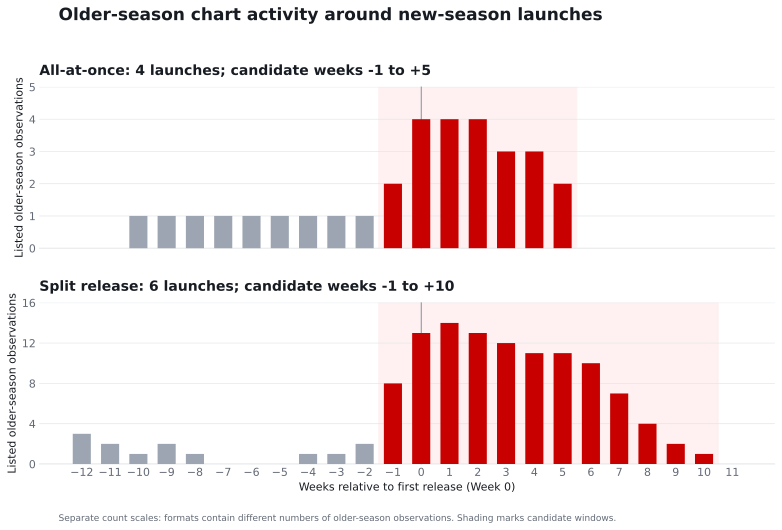

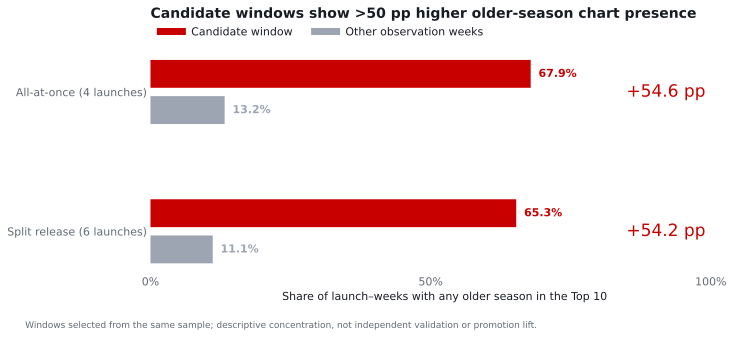

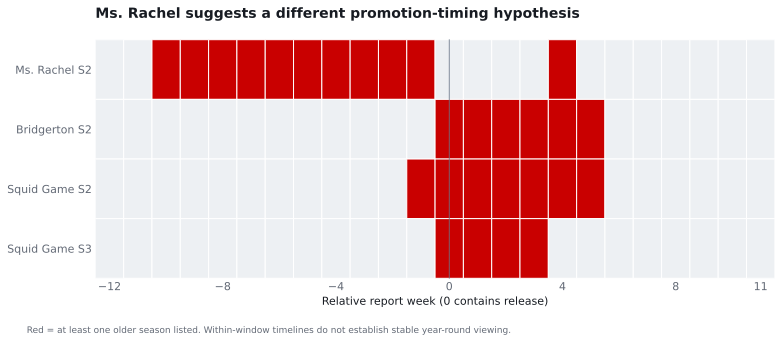

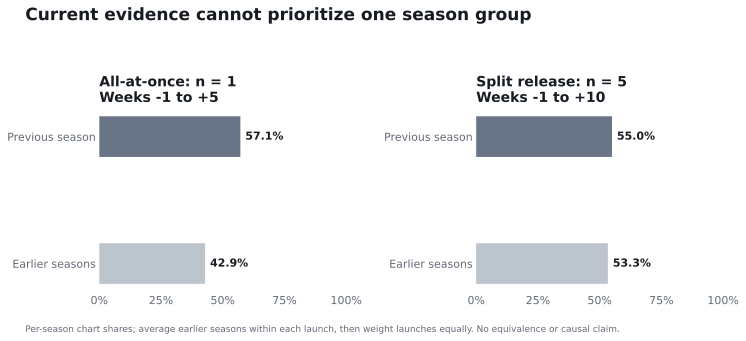

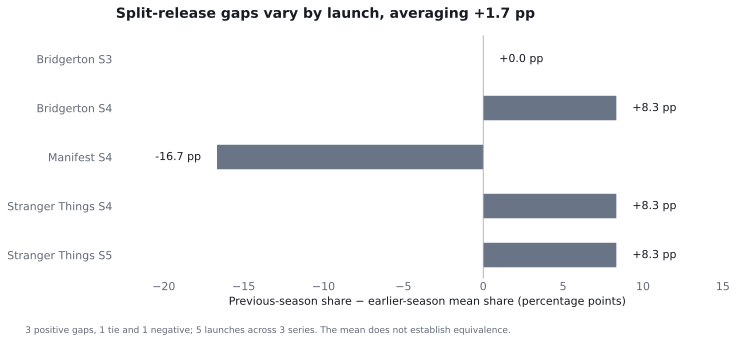

In [14]:
from plot_results import create_figures

create_figures(FIGURES, panels, window_summary, season_summary, series_event_weeks, paired_seasons)
try:
    from IPython.display import SVG
    for name in ["weekly_chart_patterns", "candidate_window_comparison", "series_timing_patterns",
                 "previous_vs_earlier", "paired_season_differences"]:
        display(SVG(filename=str(FIGURES / f"{name}.svg")))
except ImportError:
    print("Charts saved under outputs/figures.")

## 14. Proposed randomized promotion test

| Decision | Proposal |
|---|---|
| Timing | All-at-once −1 to +5; split release −1 to +10 |
| Comparison | Added older-season promotion vs. business as usual, within each format |
| Assignment | Randomize eligible users; determine eligibility using internal data |
| Primary metric | Weekly **TV viewing hours per randomized user** |
| Secondary check | Total viewing hours per randomized user to check substitution |
| Season selection | Keep previous vs. earlier selection exploratory |
| Scale-up rule | Meet a pre-agreed lift threshold without unacceptable guardrail declines |

Set eligibility, sample size, test duration and decision thresholds using internal data before launch. The public chart dataset contains no audience exposure logs, costs or user-level histories. This design tests incremental impact versus existing practice; it does not prove optimal timing or compare release formats.

## 15. Limitations and reproducibility checks

- The sample is selected and small: 10 launches across 6 series; some series contribute multiple launches.
- Below-chart viewing is unobserved. The available season list cannot enumerate every never-charted season.
- Candidate windows were chosen from the same data. The comparison describes concentration rather than independent validation.
- Later episode batches and other events may affect chart activity. Published rankings also span the historical hours-to-views ranking change.
- Season-group comparisons contain only 1 and 5 launches. Small average gaps do not prove equivalence.
- Release references are retained from the original project, not newly verified; complete charts do not prove worldwide availability for every season/week.
- No promotion experiment has been run. Chart patterns do not establish causal lift, retention or ROI.

The checks below reconcile the final presentation counts. Boundary tests in `tests/test_analysis.py` separately check window endpoints, duplicate/missing rows, all-zero observations, any-season counting and equal launch weighting.

In [15]:
from validate_results import validate_results

validation = validate_results(panels, window_summary, audit_pairs, season_summary,
    paired_seasons, series_timing, ms_rachel_snapshot)
display(validation)

{'checks': 'passed',
 'launches': 10,
 'series': 6,
 'older_season_observations': 21,
 'distinct_older_seasons': 14,
 'season_week_rows': 504,
 'launch_week_rows': 240,
 'omitted_observations': 0,
 'retained_all_zero_observations': 1}